In [1]:
# imported all the required libraries like - you can see below
# Get the data (training for now ) - problem i faced during this is that it wasnt a regular csv file , it is dir and inside it categorically divided dirs in which the image recides.
# to augment the data before getting it i used - ImageDataGenerator
# to get the data i used - ImageDataGenerator.flow_from_directory . 
#  also needed the validation data so i also get it during the flow by diving the data in 2:8 ratio with less part in validation .
#  define a model - base + head , not pretrained base.
#  define the model's optimizer .
#  define the model's callbacks
#  fit the model - got 60 percent validation accuracy
# predict using the test cases - got 60-65 % acc here also 
# For fun give it my face - in some it perform very well and in some very worse . i need to tune it more...
# key insights - used more value of batch size cause it was taking longer time on less .




#above is mine below is claude lol ->



# ============================================
# FER2013 - Facial Emotion Recognition
# ============================================

# LIBRARIES
# Imported TensorFlow, Keras, OpenCV, NumPy, Matplotlib, Seaborn
# Sklearn for confusion matrix and classification report

# DATA LOADING - Key learning
# Dataset was not a CSV like MNIST
# Images lived in folders, each folder = one emotion class
# Used ImageDataGenerator to handle augmentation + loading
# Used flow_from_directory to read folders automatically
#   - folder name becomes the label automatically
#   - resizes all images to 48x48 on the fly
#   - normalizes pixels to 0-1 with rescale=1./255
#   - returns batches of shape (64, 48, 48, 1)

# SPLITTING - Key decision
# Split train folder 80/20 using validation_split=0.2
# Did NOT touch test folder - reserved for final evaluation only
# Used same seed=42 in both generators to prevent data overlap
# Validation generator has NO augmentation - only rescale

# AUGMENTATION - Why it matters
# Without augmentation: ~50% accuracy
# With augmentation: ~60% accuracy
# Used: rotation, zoom, width/height shift
# Did NOT use horizontal_flip - faces look wrong when flipped

# MODEL ARCHITECTURE
# 6 Conv2D layers in 3 blocks (32 → 64 → 128 → 256 filters)
# Each block: Conv→BN→Conv→BN→MaxPool→Dropout
# BatchNormalization after each Conv - stabilizes training
# Dropout 0.25 after each block - prevents overfitting
# Head: Flatten → Dense(256) → BN → Dropout(0.5) → Dense(7)
# Output: 7 neurons with softmax (one per emotion)
# Total params: 1.4M

# TRAINING SETUP
# Loss: categorical_crossentropy (one-hot labels)
# Optimizer: Adam(learning_rate=0.0001)
# Callbacks:
#   ReduceLROnPlateau - cuts LR by 0.5 if no improvement for 3 epochs
#   ModelCheckpoint - saves best weights automatically
# Batch size increased from 64 to 128 for faster training on GPU

# RESULTS
# Validation accuracy: ~60%
# Test accuracy: ~60-65%
# Context: Human accuracy on FER2013 is 65% - model is near human level
# Strongest class: Happy (most training data)
# Weakest class: Disgust (only ~400 images - severe class imbalance)

# REAL WORLD TESTING - Key insights
# Tested on own face photos
# Happy photo: 98% confidence - correct
# Surprise photo: predicted neutral - wrong
# Why it failed:
#   - FER2013 trained on exaggerated expressions
#   - Real world subtle expressions harder to read
#   - 48x48 resolution loses fine details
#   - Dataset bias towards certain demographics
# This gap between test accuracy and real world = domain shift problem

# IMPROVEMENTS TO TRY NEXT
# - Transfer learning with EfficientNetB0
# - Handle class imbalance with class weights
# - Fine tune on real world photos (domain adaptation)
# - Higher resolution input images
# - Ensemble multiple models

# KEY LEARNINGS
# 1. flow_from_directory is cleaner than manual CSV loading for image datasets
# 2. Batch size affects both speed AND accuracy - tradeoff to consider
# 3. 60% on FER2013 is genuinely good - some datasets have hard ceilings
# 4. Real world performance always worse than test accuracy - domain shift
# 5. Class imbalance (disgust) hurts specific class performance badly

In [2]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
# for dirname, _, filenames in os.walk('/kaggle/input'):
#     for filename in filenames:
#         print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

In [3]:
# import tensorflow , layers , keras , sequential , Dense, MaxPool2d , conv2d, globalmaxpoolAvg ,Batchnormalization ,drooout , plot , confusionmatrix , 

In [4]:
# to_categorical , flatten , RMSprop , ImageDataGenerator , ReduceLROnPlateau , itertools,sns ,mpimg

In [5]:
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import seaborn as sns
%matplotlib inline 

np.random.seed(2)

from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix
import itertools

from tensorflow.keras.utils import to_categorical
from keras.models import Sequential 
from keras.layers import Dense, Dropout, Flatten, Conv2D, MaxPool2D
from keras.optimizers import RMSprop
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from keras.callbacks import ReduceLROnPlateau

sns.set(style='white',context='notebook',palette='deep')

2026-02-27 11:24:51.071643: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1772191491.241800      24 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1772191491.289291      24 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1772191491.670881      24 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1772191491.670936      24 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1772191491.670939      24 computation_placer.cc:177] computation placer alr

In [6]:
train_dir  = "/kaggle/input/fer2013/train"
test_dir = "/kaggle/input/fer2013/test"

In [7]:
train_datagen = ImageDataGenerator(
    width_shift_range =0.1,
    height_shift_range=0.1,
    horizontal_flip=True,
    rescale=1./255,
    validation_split=0.2
)

validation_datagen = ImageDataGenerator(
    rescale=1./255,
    validation_split=0.2
)

In [8]:
train_generator = train_datagen.flow_from_directory(
    directory=train_dir,
    target_size=(48,48),
    batch_size=64,
    color_mode="grayscale",
    class_mode = "categorical",
    subset="training",
    shuffle = True,
    seed=42
)

# validation_generator = train_datagen.flow_from_directory(
#     directory=train_dir,
#     target_size=48,
#     batch_size=64,
#     color_mode="gray_scale",
#     class_mode="categorical",
#     subset="validation",
#     shuffle= False,
#     seed=42
# )

validation_generator = validation_datagen.flow_from_directory(
    directory = train_dir,
    target_size=(48,48),
    batch_size=128,
    color_mode="grayscale",
    class_mode="categorical",
    subset="validation",
    shuffle=False,
    seed=42
)

Found 22968 images belonging to 7 classes.
Found 5741 images belonging to 7 classes.


In [9]:
from tensorflow.keras.layers import Dense, Dropout, Flatten
from tensorflow.keras.layers import Conv2D, MaxPooling2D, BatchNormalization
from tensorflow.keras.models import Sequential
import tensorflow as tf 

model = Sequential()

# Add a convolutional layer with 32 filters, 3x3 kernel size, and relu activation function
model.add(Conv2D(32, kernel_size=(3, 3), activation='relu', input_shape=(48,48,1)))
# Add a batch normalization layer
model.add(BatchNormalization())
# Add a second convolutional layer with 64 filters, 3x3 kernel size, and relu activation function
model.add(Conv2D(64, kernel_size=(3, 3), activation='relu'))
# Add a second batch normalization layer
model.add(BatchNormalization())
# Add a max pooling layer with 2x2 pool size
model.add(MaxPooling2D(pool_size=(2, 2)))
# Add a dropout layer with 0.25 dropout rate
model.add(Dropout(0.25))

# Add a third convolutional layer with 128 filters, 3x3 kernel size, and relu activation function
model.add(Conv2D(128, kernel_size=(3, 3), activation='relu'))
# Add a third batch normalization layer
model.add(BatchNormalization())
# Add a fourth convolutional layer with 128 filters, 3x3 kernel size, and relu activation function
model.add(Conv2D(128, kernel_size=(3, 3), activation='relu'))
# Add a fourth batch normalization layer
model.add(BatchNormalization())
# Add a max pooling layer with 2x2 pool size
model.add(MaxPooling2D(pool_size=(2, 2)))
# Add a dropout layer with 0.25 dropout rate
model.add(Dropout(0.25))

# Add a fifth convolutional layer with 256 filters, 3x3 kernel size, and relu activation function
model.add(Conv2D(256, kernel_size=(3, 3), activation='relu'))
# Add a fifth batch normalization layer
model.add(BatchNormalization())
# Add a sixth convolutional layer with 256 filters, 3x3 kernel size, and relu activation function
model.add(Conv2D(256, kernel_size=(3, 3), activation='relu'))
# Add a sixth batch normalization layer
model.add(BatchNormalization())
# Add a max pooling layer with 2x2 pool size
model.add(MaxPooling2D(pool_size=(2, 2)))
# Add a dropout layer with 0.25 dropout rate
model.add(Dropout(0.25))

# Flatten the output of the convolutional layers
model.add(Flatten())
# Add a dense layer with 256 neurons and relu activation function
model.add(Dense(256, activation='relu'))
# Add a seventh batch normalization layer
model.add(BatchNormalization())
# Add a dropout layer with 0.5 dropout rate
model.add(Dropout(0.5))
# Add a dense layer with 7 neurons (one for each class) and softmax activation function
model.add(Dense(7, activation='softmax'))

# model.summary()


/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
I0000 00:00:1772191526.336685      24 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 15511 MB memory:  -> device: 0, name: Tesla P100-PCIE-16GB, pci bus id: 0000:00:04.0, compute capability: 6.0


In [10]:
model.compile(loss="categorical_crossentropy", optimizer= tf.keras.optimizers.Adam(learning_rate=0.0001), metrics=['accuracy'])


In [11]:
import shutil
import os

# Copy entire dataset to working directory
print("Copying dataset...")
shutil.copytree(
    '/kaggle/input/fer2013/train',
    '/kaggle/working/train'
)
print("Done!")

# Now point your generators here instead
train_dir = '/kaggle/working/train'

Copying dataset...
Done!


In [12]:
import os
# Check if your data is in fast storage
print(os.path.exists('/kaggle/working/train'))

True


In [13]:
import time

# Time one batch
start = time.time()
images, labels = next(iter(train_generator))
end = time.time()

print(f'One batch loading time: {end-start:.2f} seconds')
print(f'Batch shape: {images.shape}')

One batch loading time: 0.17 seconds
Batch shape: (64, 48, 48, 1)


In [14]:
from tensorflow.keras.callbacks import ModelCheckpoint

# Define the callback
checkpoint_callback = ModelCheckpoint(
    filepath='model.weights.h5',
    monitor='val_accuracy',
    save_best_only=True,
    save_weights_only=True,
    mode='max',
    verbose=1
)

learning_rate_reduction = ReduceLROnPlateau(monitor='val_acc', 
                                            patience=3, 
                                            verbose=1, 
                                            factor=0.5, 
                                            min_lr=0.00001)

# Train the model with the callback
history = model.fit(
    train_generator,
    steps_per_epoch=len(train_generator),
    epochs=60,
    validation_data=validation_generator,
    validation_steps=len(validation_generator),
    callbacks=[checkpoint_callback,learning_rate_reduction]
)

/usr/local/lib/python3.12/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/60


I0000 00:00:1772191733.901512      78 service.cc:152] XLA service 0x78c3080216f0 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1772191733.901565      78 service.cc:160]   StreamExecutor device (0): Tesla P100-PCIE-16GB, Compute Capability 6.0
I0000 00:00:1772191734.765527      78 cuda_dnn.cc:529] Loaded cuDNN version 91002


  3/359 ━━━━━━━━━━━━━━━━━━━━ 22s 63ms/step - accuracy: 0.1970 - loss: 3.1185   

I0000 00:00:1772191742.106706      78 device_compiler.h:188] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


359/359 ━━━━━━━━━━━━━━━━━━━━ 0s 123ms/step - accuracy: 0.1735 - loss: 2.9588
Epoch 1: val_accuracy improved from -inf to 0.20066, saving model to model.weights.h5
359/359 ━━━━━━━━━━━━━━━━━━━━ 67s 152ms/step - accuracy: 0.1736 - loss: 2.9584 - val_accuracy: 0.2007 - val_loss: 1.9722 - learning_rate: 1.0000e-04
Epoch 2/60
  1/359 ━━━━━━━━━━━━━━━━━━━━ 44s 126ms/step - accuracy: 0.1875 - loss: 2.6343

/usr/local/lib/python3.12/dist-packages/keras/src/callbacks/callback_list.py:145: UserWarning: Learning rate reduction is conditioned on metric `val_acc` which is not available. Available metrics are: accuracy,loss,val_accuracy,val_loss,learning_rate.
  callback.on_epoch_end(epoch, logs)


359/359 ━━━━━━━━━━━━━━━━━━━━ 0s 106ms/step - accuracy: 0.2088 - loss: 2.4859
Epoch 2: val_accuracy improved from 0.20066 to 0.33775, saving model to model.weights.h5
359/359 ━━━━━━━━━━━━━━━━━━━━ 46s 128ms/step - accuracy: 0.2088 - loss: 2.4857 - val_accuracy: 0.3377 - val_loss: 1.7532 - learning_rate: 1.0000e-04
Epoch 3/60
359/359 ━━━━━━━━━━━━━━━━━━━━ 0s 105ms/step - accuracy: 0.2495 - loss: 2.2635
Epoch 3: val_accuracy improved from 0.33775 to 0.36945, saving model to model.weights.h5
359/359 ━━━━━━━━━━━━━━━━━━━━ 47s 130ms/step - accuracy: 0.2495 - loss: 2.2635 - val_accuracy: 0.3694 - val_loss: 1.6544 - learning_rate: 1.0000e-04
Epoch 4/60
359/359 ━━━━━━━━━━━━━━━━━━━━ 0s 117ms/step - accuracy: 0.2859 - loss: 2.1137
Epoch 4: val_accuracy improved from 0.36945 to 0.37729, saving model to model.weights.h5
359/359 ━━━━━━━━━━━━━━━━━━━━ 50s 138ms/step - accuracy: 0.2859 - loss: 2.1137 - val_accuracy: 0.3773 - val_loss: 1.6483 - learning_rate: 1.0000e-04
Epoch 5/60
359/359 ━━━━━━━━━━━━━━━━━

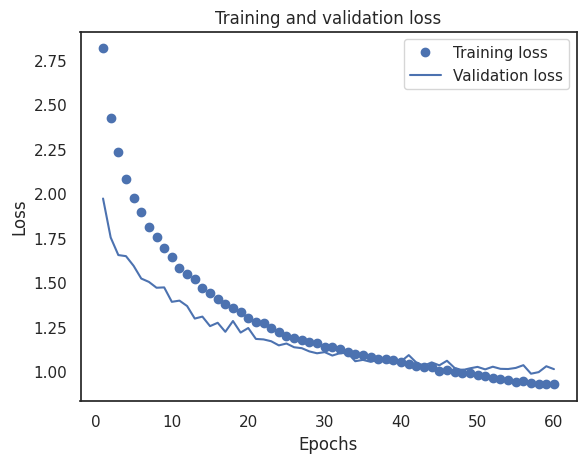

In [15]:
# Plot the train and validation loss
train_loss = history.history['loss']
val_loss = history.history['val_loss']
epochs = range(1, len(train_loss) + 1)
plt.plot(epochs, train_loss, 'bo', label='Training loss')
plt.plot(epochs, val_loss, 'b', label='Validation loss')
plt.title('Training and validation loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.show()

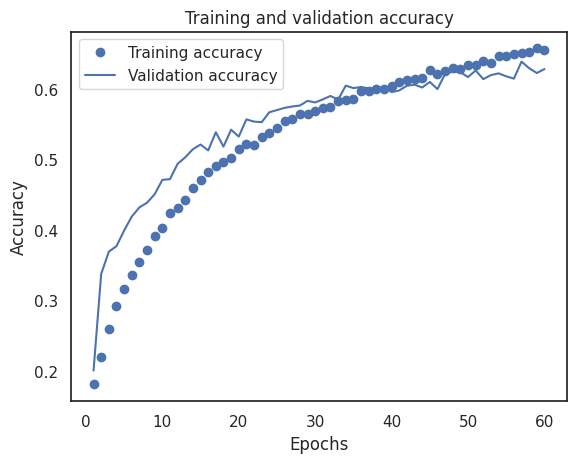

In [16]:
# Plot the train and validation accuracy
train_acc = history.history['accuracy']
val_acc = history.history['val_accuracy']
plt.plot(epochs, train_acc, 'bo', label='Training accuracy')
plt.plot(epochs, val_acc, 'b', label='Validation accuracy')
plt.title('Training and validation accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

45/45 ━━━━━━━━━━━━━━━━━━━━ 9s 176ms/step


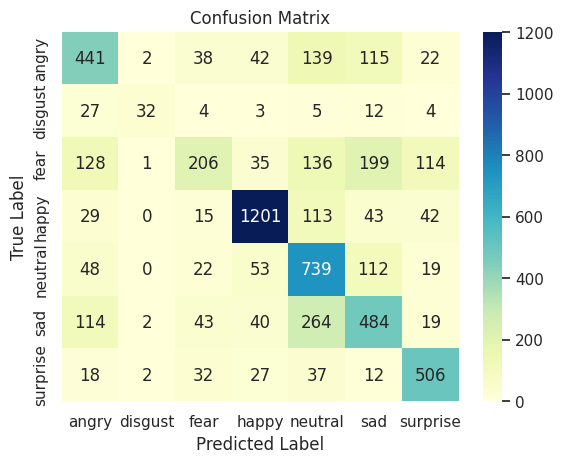

In [17]:
import seaborn as sns 
from sklearn.metrics import confusion_matrix

# Get the true labels and predicted labels for the validation set
validation_labels = validation_generator.classes
validation_pred_probs = model.predict(validation_generator)
validation_pred_labels = np.argmax(validation_pred_probs, axis=1)

# Compute the confusion matrix
confusion_mtx = confusion_matrix(validation_labels, validation_pred_labels)
class_names = list(train_generator.class_indices.keys())
sns.set()
sns.heatmap(confusion_mtx, annot=True, fmt='d', cmap='YlGnBu', 
            xticklabels=class_names, yticklabels=class_names)
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix')
plt.show()

In [18]:
test_datagen = ImageDataGenerator(rescale=1./255)

test_generator = test_datagen.flow_from_directory(
    directory='/kaggle/input/fer2013/test',  # input is fine
    target_size=(48, 48),
    batch_size=64,
    color_mode='grayscale',
    class_mode='categorical',
    shuffle=False   # critical - never shuffle test data
)

# After training finishes
model.load_weights('model.weights.h5')  # load best weights
predictions = model.predict(test_generator)

Found 7178 images belonging to 7 classes.


/usr/local/lib/python3.12/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


113/113 ━━━━━━━━━━━━━━━━━━━━ 49s 427ms/step


In [19]:
predicted_classes = np.argmax(predictions, axis=1)

# Get true labels
true_classes = test_generator.classes

# Get class names
class_names = list(test_generator.class_indices.keys())
print(class_names)
# ['angry', 'disgust', 'fear', 'happy', 'neutral', 'sad', 'surprise']

['angry', 'disgust', 'fear', 'happy', 'neutral', 'sad', 'surprise']


In [20]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(true_classes, predicted_classes)
print(f'Test Accuracy: {accuracy * 100:.2f}%')

Test Accuracy: 63.83%


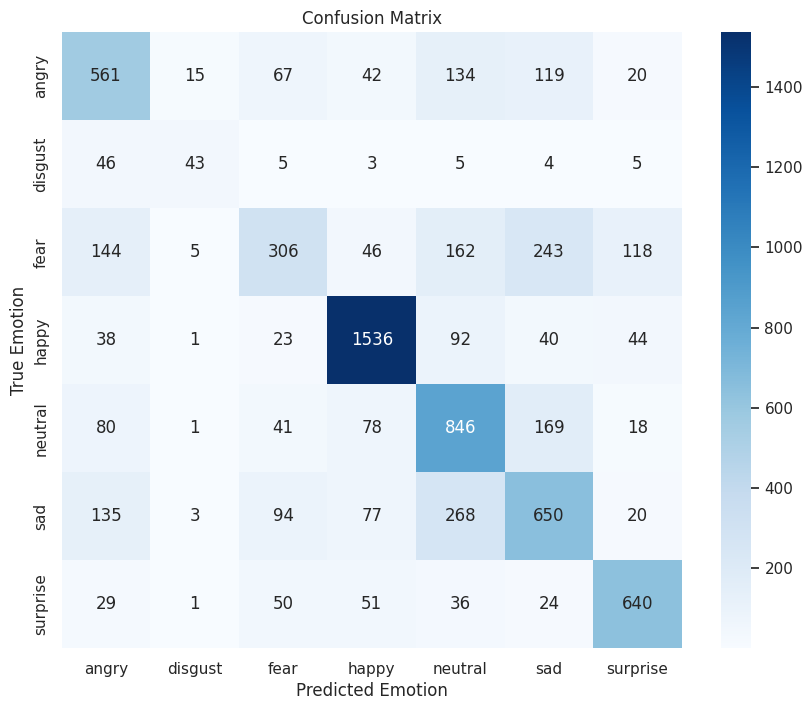

In [21]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(true_classes, predicted_classes)

plt.figure(figsize=(10, 8))
sns.heatmap(cm, 
            annot=True, 
            fmt='d',
            cmap='Blues',
            xticklabels=class_names,
            yticklabels=class_names)
plt.title('Confusion Matrix')
plt.ylabel('True Emotion')
plt.xlabel('Predicted Emotion')
plt.show()

In [22]:
def predict_emotion_from_photo(image_path):
    frame = cv2.imread(image_path)
    
    if frame is None:
        print("Image not found — check path")
        return
        
    gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
    
    # Try detecting face with relaxed parameters
    # scaleFactor=1.05 more thorough scan
    # minNeighbors=3 less strict (catches more faces)
    # minSize=(20,20) detects smaller faces too
    faces = face_cascade.detectMultiScale(
        gray,
        scaleFactor=1.05,
        minNeighbors=3,
        minSize=(20, 20)
    )
    
    if len(faces) == 0:
        print("No face detected automatically")
        print("Trying whole image as face...")
        
        # Use entire image as face
        h, w = gray.shape
        faces = [(0, 0, w, h)]
    
    print(f"Found {len(faces)} face(s)")
    
    for (x, y, w, h) in faces:
        # Add 20% padding around detected face
        # This helps when face is not perfectly centered
        pad_x = int(w * 0.2)
        pad_y = int(h * 0.2)
        
        # Make sure padding doesn't go outside image
        x1 = max(0, x - pad_x)
        y1 = max(0, y - pad_y)
        x2 = min(frame.shape[1], x + w + pad_x)
        y2 = min(frame.shape[0], y + h + pad_y)
        
        # Crop face with padding
        face = gray[y1:y2, x1:x2]
        
        # Show what model sees
        face_resized = cv2.resize(face, (48, 48))
        face_normalized = face_resized / 255.0
        face_final = face_normalized.reshape(1, 48, 48, 1)
        
        # Predict
        prediction = model.predict(face_final, verbose=0)
        emotion_idx = np.argmax(prediction)
        confidence = np.max(prediction) * 100
        
        # Draw on original image
        cv2.rectangle(frame, (x1,y1), (x2,y2), (0,255,0), 3)
        cv2.putText(frame,
                   f'{class_names[emotion_idx]} {confidence:.0f}%',
                   (x1, y1-15),
                   cv2.FONT_HERSHEY_SIMPLEX,
                   1.2, (0,255,0), 3)
        
        # Show side by side — original photo and what model sees
        fig, axes = plt.subplots(1, 3, figsize=(15, 5))
        
        # Original photo with box
        axes[0].imshow(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))
        axes[0].set_title('Your photo with detected face')
        axes[0].axis('off')
        
        # Cropped face
        axes[1].imshow(face, cmap='gray')
        axes[1].set_title('Cropped face')
        axes[1].axis('off')
        
        # What model actually sees (48x48)
        axes[2].imshow(face_resized, cmap='gray')
        axes[2].set_title('What model sees (48x48)')
        axes[2].axis('off')
        
        plt.tight_layout()
        plt.show()
        
        # Confidence bar chart
        plt.figure(figsize=(10, 4))
        bars = plt.bar(class_names, prediction[0] * 100, 
                      color='steelblue')
        bars[emotion_idx].set_color('green')
        plt.title(f'Predicted: {class_names[emotion_idx]} '
                 f'({confidence:.0f}% confident)')
        plt.ylabel('Confidence %')
        plt.xticks(rotation=45)
        plt.tight_layout()
        plt.show()
        
        print(f'Detected emotion: {class_names[emotion_idx]}')
        print(f'Confidence: {confidence:.0f}%')
        print()
        print('All emotions:')
        for name, prob in zip(class_names, prediction[0]):
            bar = '█' * int(prob * 30)
            print(f'{name:10} {bar} {prob*100:.1f}%')

# predict_emotion_from_photo('/kaggle/input/datasets/basantbansal/basant-pics/camellya-mascot-ft-shorekeeper-v0-k62e3nbvp94f1.webp')


In [23]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Load face detector
face_cascade = cv2.CascadeClassifier(
    cv2.data.haarcascades + 'haarcascade_frontalface_default.xml'
)

class_names = ['angry', 'disgust', 'fear', 'happy', 
               'neutral', 'sad', 'surprise']

In [24]:
model.save('emotion_model.keras')

Found 1 images
['WIN_20250104_22_30_42_Pro.jpg']

Processing: WIN_20250104_22_30_42_Pro.jpg
Found 1 face(s)


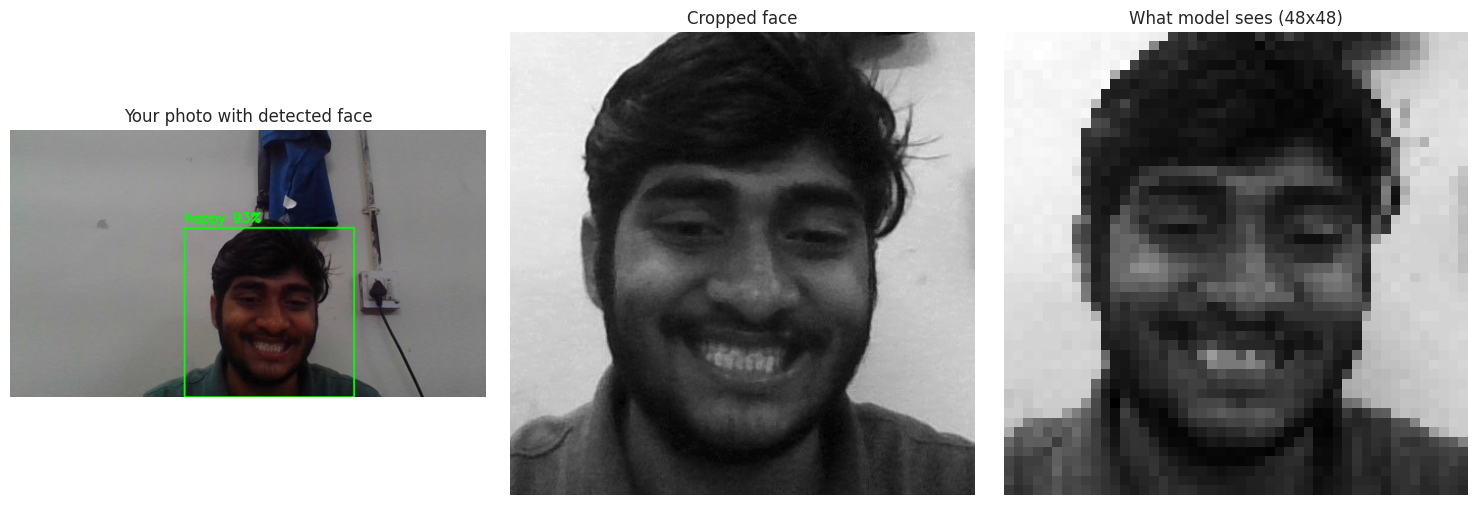

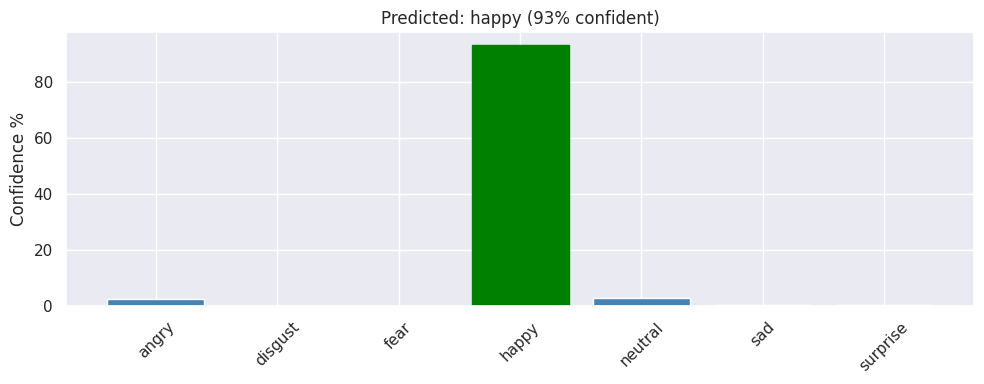

Detected emotion: happy
Confidence: 93%

All emotions:
angry       2.7%
disgust     0.0%
fear        0.1%
happy      ███████████████████████████ 93.1%
neutral     3.0%
sad         0.6%
surprise    0.5%


In [25]:
import os

# Get all images from your dataset folder
image_folder = '/kaggle/input/datasets/basantbansal/basant-photo-happy'
image_files = [f for f in os.listdir(image_folder) 
               if f.endswith(('.jpg', '.jpeg', '.png', '.JPG'))]

print(f"Found {len(image_files)} images")
print(image_files)  # see all filenames

# Run prediction on all of them
for image_file in image_files:
    image_path = os.path.join(image_folder, image_file)
    print(f"\n{'='*50}")
    print(f"Processing: {image_file}")
    print('='*50)
    predict_emotion_from_photo(image_path)